# Lab Assignment 8

## 1. Support Vector Machine (SVM) Using Different Kernels

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report


In [ ]:

data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset Shape:", X.shape)
print("Classes:", data.target_names)


Dataset Shape: (569, 30)
Classes: ['malignant' 'benign']


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])


Training Samples: 455
Testing Samples: 114


In [ ]:

kernels = ["linear", "poly", "rbf", "sigmoid"]
results = []

for kernel in kernels:
    model = SVC(kernel=kernel, random_state=42)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        "Kernel": kernel,
        "Accuracy (%)": accuracy * 100,
        "Support Vectors": model.n_support_.sum()
    })

results_df = pd.DataFrame(results)
print(results_df)


    Kernel  Accuracy (%)  Support Vectors
0   linear     97.368421               32
1     poly     91.228070              145
2      rbf     98.245614               97
3  sigmoid     92.982456               66


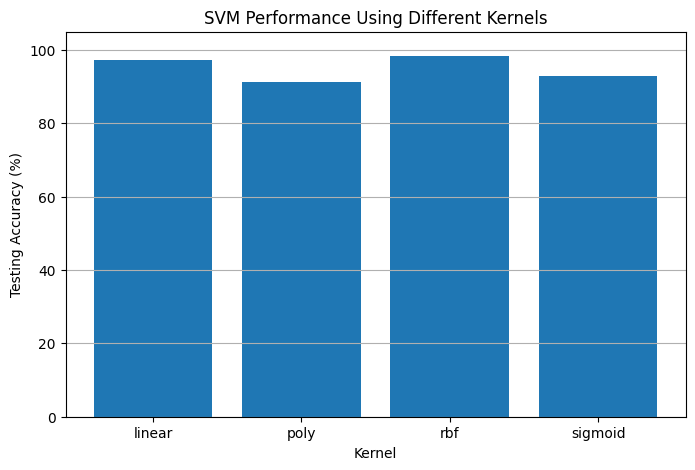

In [ ]:

plt.figure(figsize=(8, 5))

plt.bar(
    results_df["Kernel"],
    results_df["Accuracy (%)"]
)

plt.title("SVM Performance Using Different Kernels")
plt.xlabel("Kernel")
plt.ylabel("Testing Accuracy (%)")
plt.ylim(0, 105)
plt.grid(axis="y")
plt.show()



## 2. Decision Tree Implementation From Scratch Using Entropy and Gini Index


In [ ]:

data = pd.DataFrame({
    "Outlook": ["Sunny", "Sunny", "Overcast", "Rain", "Rain",
                "Rain", "Overcast", "Sunny", "Sunny", "Rain",
                "Sunny", "Overcast", "Overcast", "Rain"],
    "Temperature": ["Hot", "Hot", "Hot", "Mild", "Cool",
                    "Cool", "Cool", "Mild", "Cool", "Mild",
                    "Mild", "Mild", "Hot", "Mild"],
    "Humidity": ["High", "High", "High", "High", "Normal",
                 "Normal", "Normal", "High", "Normal", "Normal",
                 "Normal", "High", "Normal", "High"],
    "Wind": ["Weak", "Strong", "Weak", "Weak", "Weak",
             "Strong", "Strong", "Weak", "Weak", "Weak",
             "Strong", "Strong", "Weak", "Strong"],
    "Play": ["No", "No", "Yes", "Yes", "Yes",
             "No", "Yes", "No", "Yes", "Yes",
             "Yes", "Yes", "Yes", "No"]
})

print(data)


     Outlook Temperature Humidity    Wind Play
0      Sunny         Hot     High    Weak   No
1      Sunny         Hot     High  Strong   No
2   Overcast         Hot     High    Weak  Yes
3       Rain        Mild     High    Weak  Yes
4       Rain        Cool   Normal    Weak  Yes
5       Rain        Cool   Normal  Strong   No
6   Overcast        Cool   Normal  Strong  Yes
7      Sunny        Mild     High    Weak   No
8      Sunny        Cool   Normal    Weak  Yes
9       Rain        Mild   Normal    Weak  Yes
10     Sunny        Mild   Normal  Strong  Yes
11  Overcast        Mild     High  Strong  Yes
12  Overcast         Hot   Normal    Weak  Yes
13      Rain        Mild     High  Strong   No


In [ ]:

def entropy(y):
    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return -np.sum(probabilities * np.log2(probabilities))


def gini(y):
    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return 1 - np.sum(probabilities ** 2)


print("Entropy:", entropy(data["Play"]))
print("Gini Index:", gini(data["Play"]))


Entropy: 0.9402859586706311
Gini Index: 0.4591836734693877


In [ ]:

def calculate_gains(df, feature, target):
    parent_entropy = entropy(df[target])
    parent_gini = gini(df[target])

    weighted_entropy = 0
    weighted_gini = 0

    for value in df[feature].unique():
        subset = df[df[feature] == value]
        weight = len(subset) / len(df)

        weighted_entropy += weight * entropy(subset[target])
        weighted_gini += weight * gini(subset[target])

    information_gain = parent_entropy - weighted_entropy
    gini_gain = parent_gini - weighted_gini

    return information_gain, gini_gain


for feature in data.columns[:-1]:
    ig, gg = calculate_gains(data, feature, "Play")
    print(feature, "Information Gain:", round(ig, 4),
          "Gini Gain:", round(gg, 4))


Outlook Information Gain: 0.2467 Gini Gain: 0.1163
Temperature Information Gain: 0.0292 Gini Gain: 0.0187
Humidity Information Gain: 0.1518 Gini Gain: 0.0918
Wind Information Gain: 0.0481 Gini Gain: 0.0306


In [ ]:

def build_tree(df, features, target, criterion="entropy"):
    labels = df[target]

    if len(labels.unique()) == 1:
        return labels.iloc[0]

    if not features:
        return labels.mode()[0]

    gains = [calculate_gains(df, f, target) for f in features]

    scores = [g[0] if criterion == "entropy" else g[1] for g in gains]
    best_feature = features[np.argmax(scores)]

    if max(scores) <= 0:
        return labels.mode()[0]

    tree = {"feature": best_feature, "branches": {}}
    remaining = [f for f in features if f != best_feature]

    for value in df[best_feature].unique():
        subset = df[df[best_feature] == value]
        tree["branches"][value] = build_tree(
            subset, remaining, target, criterion
        )

    return tree


In [ ]:


features = list(data.columns[:-1])

tree_entropy = build_tree(data, features, "Play", "entropy")
tree_gini = build_tree(data, features, "Play", "gini")

print("Entropy Tree:", tree_entropy)
print("Gini Tree:", tree_gini)


Entropy Tree: {'feature': 'Outlook', 'branches': {'Sunny': {'feature': 'Humidity', 'branches': {'High': 'No', 'Normal': 'Yes'}}, 'Overcast': 'Yes', 'Rain': {'feature': 'Wind', 'branches': {'Weak': 'Yes', 'Strong': 'No'}}}}
Gini Tree: {'feature': 'Outlook', 'branches': {'Sunny': {'feature': 'Humidity', 'branches': {'High': 'No', 'Normal': 'Yes'}}, 'Overcast': 'Yes', 'Rain': {'feature': 'Wind', 'branches': {'Weak': 'Yes', 'Strong': 'No'}}}}


In [ ]:

predictions = [
    predict_tree(tree_entropy, row, data["Play"].mode()[0])
    for _, row in data.iterrows()
]

print("Actual Labels:", data["Play"].tolist())
print("Predicted Labels:", predictions)
print("Training Accuracy:",
      accuracy_score(data["Play"], predictions) * 100, "%")


Actual Labels: ['No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'No']
Predicted Labels: ['No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'No']
Training Accuracy: 100.0 %



## 3. K-Nearest Neighbors (KNN) Classification


In [ ]:

from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

iris = load_iris()
X = iris.data
y = iris.target

print("Dataset Shape:", X.shape)
print("Classes:", iris.target_names)


Dataset Shape: (150, 4)
Classes: ['setosa' 'versicolor' 'virginica']


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))


Training Samples: 120
Testing Samples: 30


In [ ]:

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

print("Training Accuracy:", knn.score(X_train, y_train) * 100, "%")
print("Testing Accuracy:", accuracy_score(y_test, y_pred) * 100, "%")


Training Accuracy: 97.5 %
Testing Accuracy: 93.33333333333333 %


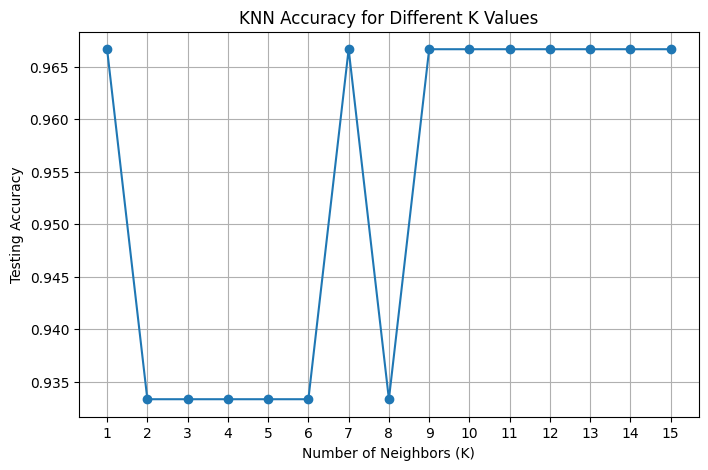

Best K: 1


In [ ]:

k_values = range(1, 16)
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    accuracies.append(model.score(X_test, y_test))

plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, marker="o")
plt.title("KNN Accuracy for Different K Values")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Testing Accuracy")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

print("Best K:", list(k_values)[np.argmax(accuracies)])
